# **1. 시퀀스 데이터**

시퀀스 데이터(Sequence Data)는 **시간적 혹은 순서적 관계가 중요한 데이터**를 말한다. 일반적인 데이터가 순서와 무관하게 독립적으로 다뤄지는 것과 달리, 시퀀스 데이터는 각 요소가 특정 순서에 따라 나열되어 있고 앞뒤 맥락이 의미를 가진다. 대표적인 예로는 자연어 문장(단어의 순서 중요), 시계열 데이터(주가, 날씨 변화), 음성 신호(시간에 따른 파형), 영상 프레임(연속된 이미지) 등이 있다. 따라서, 시퀀스 데이터는 단순한 값들의 모음이 아니라, 순서와 맥락이 포함된 정보 구조로 이해하는 것이 핵심이다.

# **2. RNN**

RNN(Recurrent Neural Network, 순환 신경망)은 시계열 데이터나 연속적인 데이터를 다룰 때 사용되는 인공 신경망으로, 일반적인 신경망(CNN, MLP 등)이 입력을 한 번 처리하고 끝나는 것과 달리, **과거의 정보를 기억하며 다음 계산에 반영하는 특징**이 있다. 일반적인 신경망은 현재 입력만 보고 예측하지만, 시계열 데이터나 자연어처럼 이전 정보가 중요한 경우에는 적절하지 않기 때문에 RNN이 필요하다. RNN은 기존 신경망과 달리 자신의 출력을 다시 입력으로 사용하여 과거 정보를 기억하는 구조를 가지며, 이를 통해 시계열 데이터의 패턴을 학습할 수 있다.  그러나 일반적인 RNN은 장기 의존성(Long-Term Dependency) 문제로 인해 학습이 어려울 수 있으며, 이를 해결하기 위해 장단기 메모리(Long Short-Term Memory, LSTM)나 게이트 순환 유닛(Gated Recurrent Unit, GRU)과 같은 변형 모델이 개발되었다. 

![RNN1](./images/RNN1.png)

![RNN2](./images/RNN2.png)

### RNN 구조
```
[batch_size, sequnece_length, input_size] # RNN input: 3차원 구조
예시) [32, 20, 10] # 32개의 시퀀스를 처리하고, 한 시퀀스는 20이며, 하루마다 10개의 특성이 있음
```

![RNN3](./images/RNN3.png)

> 이전 시점의 hidden state를 다음 시점으로 계속 넘긴다는 것이다.

# **3. RNN을 이용한 KOSPI 예측**

20일의 KOSPI 데이터를 넣는다고 가정하면 RNN은 개념적으로 아래처럼 움직인다.
```
1일차 데이터 입력 + 초기 기억 -> 1일차 기억
2일차 데이터 입력 + 1일차 기억 -> 2일차 기억
3일차 데이터 입력 + 2일차 기억 -> 3일차 기억
...
20일차 데이터 입력 + 19일차 기억 -> 20일차 기억>
```
> 20일차의 최종 hidden state를 linear layer에 넣어 다음날 종가를 예측하게 만드는 것이 목적이다.

### Hidden State
RNN의 기억(memory), 지금까지 들어온 입력에서 다음 계산이 필요하다가 RNN이 학습한 정보를 압축한 벡터이다.
- 예시) hidden_size=64라면 각 시점에서 RNN은 64개의 숫자로 이루어진 hidden state를 만든다.
    - input_szie: 하루에 입력되는 특성 개수
    - sequence_length: 며칠을 볼 것인지
    - hidden_size: 내부에서 정보를 몇 개의 숫자로 표현할 것인지

### tanh를 사용하는 이유
tanh는 입력값을 -1 ~ 1 사이로 변환해주는 함수이다. RNN에서는 이전 hidden state가 다음 시점 계산에 계속 재사용되기 때문에 값이 지나치게 커지는 것을 억제하는데 도움을 준다.
※ 시퀀스가 길어지면 tanh와 반복적인 행렬 곱 때문에 기울기 소실 문제가 발생할 수 있다.

### RNN의 한계
RNN은 가까운 과거 정보는 비교적 잘 사용할 수 있다. 하지만, 오래된 정보까지 안정적으로 기억하는 것은 어렵다(장기 의존성 문제). 그래서 긴 시퀀스에서는 LSTM, GRU, Transformer 계열 모델이 많이 사용된다.
- 기본 RNN은 순한 신경망의 hidden state와 시계열 입력 구조를 이해하기에 매우 좋은 출발점이다.

In [1]:
import copy
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [2]:
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cpu


In [3]:
SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [4]:
df = pd.read_csv("./data/kospi.csv")
df

,Date,Open,High,Low,Close,Adj Close,Volume
0,04/01/2000,1028.329956,1066.180054,1016.590027,1059.040039,1059.040039,19589800.0
1,05/01/2000,1006.869995,1026.520020,984.049988,986.309998,986.309998,25769600.0
2,06/01/2000,1013.950012,1014.900024,953.500000,960.789978,960.789978,20352300.0
3,07/01/2000,949.169983,970.159973,930.840027,948.650024,948.650024,21566400.0
4,10/01/2000,979.669983,994.940002,974.820007,987.239990,987.239990,24017500.0
...,...,...,...,...,...,...,...
4508,16/01/2018,2504.159912,2524.550049,2498.550049,2521.739990,2521.739990,341600.0
4509,17/01/2018,2517.189941,2521.969971,2506.489990,2515.429932,2515.429932,336700.0
4510,18/01/2018,2527.669922,2532.080078,2512.689941,2515.810059,2515.810059,333100.0
4511,19/01/2018,2519.669922,2524.330078,2513.090088,2520.260010,2520.260010,351800.0


In [5]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True, errors='coerce') # dayfirst=True: ddmmyy 형식, errors='coerce': 오류나면 NaN
df

,Date,Open,High,Low,Close,Adj Close,Volume
0,2000-01-04,1028.329956,1066.180054,1016.590027,1059.040039,1059.040039,19589800.0
1,2000-01-05,1006.869995,1026.520020,984.049988,986.309998,986.309998,25769600.0
2,2000-01-06,1013.950012,1014.900024,953.500000,960.789978,960.789978,20352300.0
3,2000-01-07,949.169983,970.159973,930.840027,948.650024,948.650024,21566400.0
4,2000-01-10,979.669983,994.940002,974.820007,987.239990,987.239990,24017500.0
...,...,...,...,...,...,...,...
4508,2018-01-16,2504.159912,2524.550049,2498.550049,2521.739990,2521.739990,341600.0
4509,2018-01-17,2517.189941,2521.969971,2506.489990,2515.429932,2515.429932,336700.0
4510,2018-01-18,2527.669922,2532.080078,2512.689941,2515.810059,2515.810059,333100.0
4511,2018-01-19,2519.669922,2524.330078,2513.090088,2520.260010,2520.260010,351800.0


In [6]:
numeric_cols = ["Open", "High", "Low", "Close", "Adj Close", "Volume"]

for col in numeric_cols:
    if col in numeric_cols:
        df[col] = pd.to_numeric(df[col], errors='coerce')

In [7]:
required_cols = ["Date", "Open", "High", "Low", "Close"]
missing_col = [col for col in required_cols if col not in df.columns]
missing_col

[]

In [8]:
df = df.dropna(subset=required_cols).copy()

In [9]:
df = df.sort_values("Date").reset_index(drop=True)
print('데이터 기간:', df['Date'].min(), '~', df['Date'].max())
print('전체 행 수:', len(df))
df.head()

데이터 기간: 2000-01-04 00:00:00 ~ 2018-01-22 00:00:00
전체 행 수: 4452


,Date,Open,High,Low,Close,Adj Close,Volume
0,2000-01-04,1028.329956,1066.180054,1016.590027,1059.040039,1059.040039,19589800.0
1,2000-01-05,1006.869995,1026.520020,984.049988,986.309998,986.309998,25769600.0
2,2000-01-06,1013.950012,1014.900024,953.500000,960.789978,960.789978,20352300.0
3,2000-01-07,949.169983,970.159973,930.840027,948.650024,948.650024,21566400.0
4,2000-01-10,979.669983,994.940002,974.820007,987.239990,987.239990,24017500.0


### 데이터 확인
- 시계열에서는 날짜 순서가 중요하다. 
- 반드시 날짜 오름차순인지 확인해야 한다.

<class 'pandas.DataFrame'>
RangeIndex: 4452 entries, 0 to 4451
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       4452 non-null   datetime64[us]
 1   Open       4452 non-null   float64       
 2   High       4452 non-null   float64       
 3   Low        4452 non-null   float64       
 4   Close      4452 non-null   float64       
 5   Adj Close  4452 non-null   float64       
 6   Volume     4452 non-null   float64       
dtypes: datetime64[us](1), float64(6)
memory usage: 243.6 KB
None

결측치 개수
Open     0
High     0
Low      0
Close    0
dtype: int64


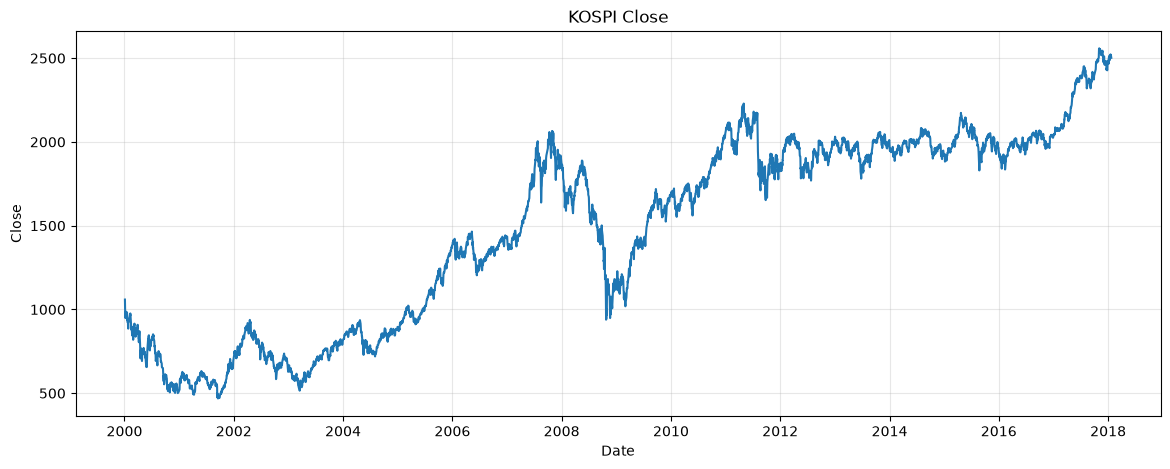

In [10]:
print(df.info())
print()
print("결측치 개수")
print(df[["Open", "High", "Low", "Close"]].isna().sum())

plt.figure(figsize=(14, 5))
plt.plot(df["Date"], df["Close"])
plt.title("KOSPI Close")
plt.xlabel("Date")
plt.ylabel("Close")
plt.grid(alpha=0.3)
plt.show()

### Feature Engineering
사용하는 특성
- Open, High, Low, Close
- Return_1d: 전일 대비 종가 수익률
- Range_pct: 하루 고가-저가 범위
- OC_pct: 시가 대비 종가 변화율
- MA5_ratio: 종가 / 5일 이동평균
- MA20_ratio: 종가 / 20일 이동평균
- Volatility_10: 최근 10일 수익률 표준편차

목표값은 다음 거래일의 종가
```
현재 날짜: t
입력: t일까지의 정보
정답: t+1일의 Close
```

In [11]:
data = df.copy()

data["Return_1d"] = data["Close"].pct_change()
data["Range_pct"] = (data["High"] - data["Low"]) / data["Close"]
data["OC_pct"] = (data["Close"] - data["Open"]) / data["Open"]

data["MA5"] = data["Close"].rolling(5).mean()
data["MA20"] = data["Close"].rolling(20).mean()

data["MA5_ratio"] = data["Close"] / data["MA5"]
data["MA20_ratio"] = data["Close"] / data["MA20"]

data["Volatility_10"] = data["Return_1d"].rolling(10).std()

# 다음 거래일 종가와 날짜를 정답으로 사용합니다.
data["Target_Close"] = data["Close"].shift(-1)
data["Target_Date"] = data["Date"].shift(-1)

FEATURES = [
    "Open",
    "High",
    "Low",
    "Close",
    "Return_1d",
    "Range_pct",
    "OC_pct",
    "MA5_ratio",
    "MA20_ratio",
    "Volatility_10",
]

# rolling으로 생긴 앞부분 NaN과 마지막 target NaN을 제거합니다.
data = data.dropna(subset=FEATURES + ["Target_Close", "Target_Date"]).reset_index(drop=True)

print("사용할 Feature 개수:", len(FEATURES))
print("정제 후 데이터 수:", len(data))
print(data.shape)
data[["Date"] + FEATURES + ["Target_Date", "Target_Close"]].head()

사용할 Feature 개수: 10
정제 후 데이터 수: 4432
(4432, 17)


,Date,Open,High,Low,Close,Return_1d,Range_pct,OC_pct,MA5_ratio,MA20_ratio,Volatility_10,Target_Date,Target_Close
0,2000-01-31,924.830017,948.840027,922.919983,943.880005,0.002347,0.027461,0.020598,1.032344,0.990929,0.025395,2000-02-01,928.750000
1,2000-02-01,955.440002,959.309998,923.520020,928.750000,-0.016030,0.038536,-0.027935,1.007524,0.981760,0.025668,2000-02-02,943.590027
2,2000-02-02,929.690002,950.130005,923.400024,943.590027,0.015978,0.028328,0.014951,1.010891,0.999704,0.022495,2000-02-03,950.219971
3,2000-02-03,950.260010,959.000000,934.109985,950.219971,0.007026,0.026194,-0.000042,1.009131,1.007292,0.022477,2000-02-07,973.130005
4,2000-02-07,953.229980,982.030029,951.309998,973.130005,0.024110,0.031568,0.020876,1.026602,1.030241,0.022042,2000-02-08,961.219971


### Train/Val/Test 시간 순 분리
시계열 데이터에서 가장 중요한 원칙 중 하나는 미래 데이터를 학습에 사용하지 않는 것이다.
- 데이터를 섞지 않고 시간 순으로 train(70%), val(15%), test(15%)로 나눈다.
> 미래 데이터를 학습해서 train accuracy가 높으나 검증 시에는 accuracy가 낮게 나오는 경우를 데이터 누수라 한다.

In [12]:
n = len(data)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

print("Train rows :", train_end)
print("Valid rows :", val_end - train_end)
print("Test rows  :", n - val_end)

print()
print("Train target 기간:",
      data.loc[0, "Target_Date"], "~",
      data.loc[train_end - 1, "Target_Date"])

print("Valid target 기간:",
      data.loc[train_end, "Target_Date"], "~",
      data.loc[val_end - 1, "Target_Date"])

print("Test target 기간 :",
      data.loc[val_end, "Target_Date"], "~",
      data.loc[n - 1, "Target_Date"])

Train rows : 3102
Valid rows : 665
Test rows  : 665

Train target 기간: 2000-02-01 00:00:00 ~ 2012-08-20 00:00:00
Valid target 기간: 2012-08-21 00:00:00 ~ 2015-05-04 00:00:00
Test target 기간 : 2015-05-06 00:00:00 ~ 2018-01-22 00:00:00


### Scaling
- 신경망은 입력 특성들의 숫자 크기가 지나치게 크거나, 피처들이 다르면 학습하기 어려울 수 있다.
- Scaler(StandardScaler)의 평균과 표준편차를 계산하는 fit()는 train 데이터 만 수행한다.
- Val/Test 데이터까지 포함해서 fit()하면 미래 데이터의 통계 정보가 학습 단계에 들어가는 데이터 누수가 될 수 있다.

In [13]:
scaler_x = StandardScaler()
scaler_y = StandardScaler()

# fit은 오직 Train 구간에서만 수행
scaler_x.fit(data.loc[:train_end - 1, FEATURES])
scaler_y.fit(data.loc[:train_end - 1, ["Target_Close"]])

# transform은 같은 scaler로 전체 데이터에 적용
X_all = scaler_x.transform(data[FEATURES]).astype(np.float32)
y_all = scaler_y.transform(data[["Target_Close"]]).astype(np.float32)

print("X_all shape:", X_all.shape)
print("y_all shape:", y_all.shape)

X_all shape: (4432, 10)
y_all shape: (4432, 1)


### 시퀀스 만들기
- 최근 20 거래일을 보고 다음 거래일 종가를 예측할 수 있어야 한다.
- 전체 시계열에서 window를 만든 뒤, 정답(target)의 시점에 따라 train/val/test 구분해야 한다.
- 위와 같이 window를 사용해야 test 시작 첫날을 예측할 때도 바로 앞의 train/val 구간 데이터를 과거 정보를 사용할 수 있다.

In [15]:
SEQUENCE_LENGTH = 20

def make_sequences(X, y, sequence_length):
    X_seq = []
    y_seq = []
    target_indices = []

    # i = 현재까지 관측한 마지막 행
    # X는 i를 포함한 최근 sequence_length개
    # y[i]는 data[i] 다음 거래일의 종가
    for i in range(sequence_length - 1, len(X)):
        start = i - sequence_length + 1

        X_seq.append(X[start:i + 1])
        y_seq.append(y[i])
        target_indices.append(i)

    return (
        np.asarray(X_seq, dtype=np.float32),
        np.asarray(y_seq, dtype=np.float32),
        np.asarray(target_indices, dtype=np.int64),
    )

X_seq, y_seq, target_indices = make_sequences(
    X_all,
    y_all,
    SEQUENCE_LENGTH
)

print("전체 sequence shape:", X_seq.shape)
print("전체 target shape  :", y_seq.shape)
print("target index shape :", target_indices.shape)

전체 sequence shape: (4413, 20, 10)
전체 target shape  : (4413, 1)
target index shape : (4413,)


### 텐서 모양 읽기
```
x_seq.shape가 예를 들어 (6000, 20, 10)이라면
- 6000: 만들어진 시퀀스 개수
- 20: 한 시퀀스에 포함된 거래일 수
- 10: 하루에 들어가는 feature 개수
```

In [16]:
train_mask = target_indices < train_end
val_mask = (target_indices >= train_end) & (target_indices < val_end)
test_mask = target_indices >= val_end

X_train = X_seq[train_mask]
y_train = y_seq[train_mask]

X_val = X_seq[val_mask]
y_val = y_seq[val_mask]

X_test = X_seq[test_mask]
y_test = y_seq[test_mask]

idx_train = target_indices[train_mask]
idx_val = target_indices[val_mask]
idx_test = target_indices[test_mask]

print("Train:", X_train.shape, y_train.shape)
print("Valid:", X_val.shape, y_val.shape)
print("Test :", X_test.shape, y_test.shape)

Train: (3083, 20, 10) (3083, 1)
Valid: (665, 20, 10) (665, 1)
Test : (665, 20, 10) (665, 1)


### Dataset과 Dataloader
- RNN은 한번에 전체 데이터를 넣기보다 mini-batch 단위로 넣는다. 
- 학습 dataloader의 shuffle=True는 각 시퀀스 내부의 날짜 순서를 섞는 것이 아니다. 
- 이미 만들어진 20일짜리 window들의 순서만 배치 구성 단계에서 섞는다.
- 각 window 내부의 1일, 2일, ... , 20일 순서는 그대로 유지한다.
- 이번 RNN 모델은 각 window마다 hidden state를 0에서 시작하는 방식이므로 학습 window의 batch 순서로 섞어도 무방하다.

In [17]:
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

BATCH_SIZE = 64

train_loader = DataLoader(
    SequenceDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    SequenceDataset(X_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    SequenceDataset(X_test, y_test),
    batch_size=BATCH_SIZE,
    shuffle=False
)

xb, yb = next(iter(train_loader))

print("한 배치 X:", xb.shape)
print("한 배치 y:", yb.shape)

한 배치 X: torch.Size([64, 20, 10])
한 배치 y: torch.Size([64, 1])


### PyTorch RNN 모델
- nn.RNN(..., batch_first=True)에 입력되는 텐서는 [batch, sequence,_length, input_size] 형태
- 출력: out = [batch, sequence,_length, hidden_size]
- 출력에서 모든 시점 중 마지막 시점의 hidden state는 out[:, -1, :]만 가져와 linear layer에 넣어 다음날 종가 한 개를 예측할 수 있다.
- 회귀 문제의 출력값은 0 ~ 1로 제한할 필요가 없으므로 마지막 층은 linear 출력 그래도 사용한다.

In [ ]:
class RNNRegressor(nn.Module):
    def __init__(
        self,
        input_size,
        hidden_size=64,
        num_layers=2,
        dropout=0.10
    ):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            nonlinearity="tanh",
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        # 초기 hidden state를 직접 주지 않으면 PyTorch가 0으로 초기화합니다.
        # out: 모든 time step의 마지막 RNN layer 출력
        # h_n: RNN layer의 마지막 hidden state
        # 단방향 RNN에서는 [num_layers, batch, hidden] 형태
        out, h_n = self.rnn(x)

        # out shape:
        # [batch, sequence_length, hidden_size]
        last_hidden = out[:, -1, :] # h_n[-1]

        pred = self.fc(last_hidden)
        return pred


model = RNNRegressor(
    input_size=len(FEATURES),
    hidden_size=64,
    num_layers=2,
    dropout=0.10
).to(DEVICE)

print(model)

RNNRegressor(
  (rnn): RNN(10, 64, num_layers=2, batch_first=True, dropout=0.1)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [19]:
# 텐서 모양 직접 확인
model.eval()

with torch.no_grad():
    sample_x = xb[:4].to(DEVICE)

    out, h_n = model.rnn(sample_x)

print("입력 sample_x :", sample_x.shape)
print("RNN out       :", out.shape)
print("RNN h_n       :", h_n.shape)
print("마지막 시점    :", out[:, -1, :].shape)

입력 sample_x : torch.Size([4, 20, 10])
RNN out       : torch.Size([4, 20, 64])
RNN h_n       : torch.Size([2, 4, 64])
마지막 시점    : torch.Size([4, 64])


### Loss와 Optimaizer
- HuberLoss
    
    주가 데이터에는 급등/급락처럼 큰 오차가 발생할 수 있다. 따라서, 작은 오차에서는 MSE처럼 부드럽게 동작하고, 큰 오차에서는 MSE보다 이상치의 영향을 완만하게 받게 한다.

In [20]:
criterion = nn.HuberLoss(delta=1.0)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5
)

MAX_EPOCHS = 200
PATIENCE = 15
CLIP_NORM = 1.0

In [21]:
def evaluate_loss(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_count = 0

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            pred = model(xb)
            loss = criterion(pred, yb)

            batch_size = xb.size(0)
            total_loss += loss.item() * batch_size
            total_count += batch_size

    return total_loss / total_count


best_val_loss = float("inf")
best_state = None
wait = 0

train_history = []
val_history = []

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()

    train_loss_sum = 0.0
    train_count = 0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        pred = model(xb)
        loss = criterion(pred, yb)

        loss.backward()

        torch.nn.utils.clip_grad_norm_( # inplace 함수: 새로운 결과를 따로 만들어서 반환하는 게 아니라, 원본 데이터 자체를 직접 수정하는 함수
            model.parameters(),
            max_norm=CLIP_NORM
        )

        optimizer.step()

        batch_size = xb.size(0)
        train_loss_sum += loss.item() * batch_size
        train_count += batch_size

    train_loss = train_loss_sum / train_count
    val_loss = evaluate_loss(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    train_history.append(train_loss)
    val_history.append(val_loss)

    scheduler.step(val_loss)

    if val_loss < best_val_loss - 1e-6:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1

    if epoch == 1 or epoch % 10 == 0:
        lr = optimizer.param_groups[0]["lr"]
        print(
            f"Epoch {epoch:03d} | "
            f"Train {train_loss:.6f} | "
            f"Valid {val_loss:.6f} | "
            f"LR {lr:.2e}"
        )

    if wait >= PATIENCE:
        print(f"\nEarly Stopping: epoch {epoch}")
        break

# 가장 Validation 성능이 좋았던 가중치 복원
if best_state is not None:
    model.load_state_dict(best_state)

print("Best validation loss:", best_val_loss)

Epoch 001 | Train 0.054895 | Valid 0.001435 | LR 1.00e-03
Epoch 010 | Train 0.001986 | Valid 0.001155 | LR 1.00e-03
Epoch 020 | Train 0.001413 | Valid 0.000466 | LR 1.00e-03
Epoch 030 | Train 0.001305 | Valid 0.000558 | LR 5.00e-04

Early Stopping: epoch 34
Best validation loss: 0.0004134397262259197


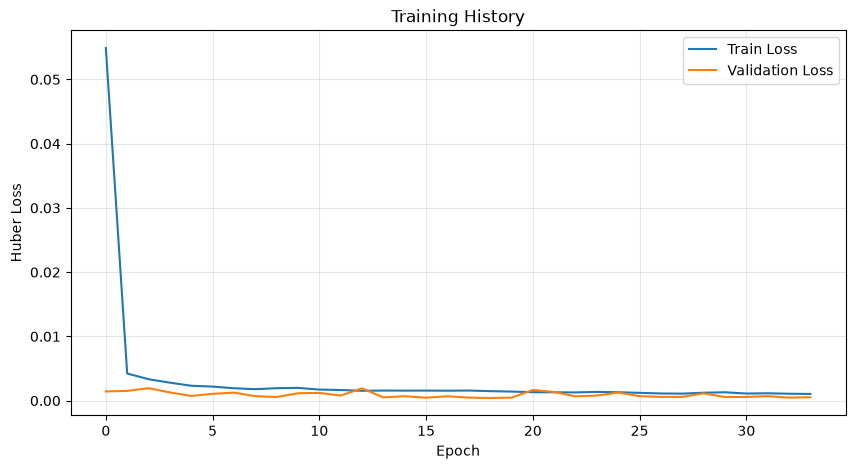

In [22]:
plt.figure(figsize=(10, 5))
plt.plot(train_history, label="Train Loss")
plt.plot(val_history, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Huber Loss")
plt.title("Training History")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [23]:
def predict(model, loader, device):
    model.eval()

    preds = []
    trues = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)

            pred = model(xb)

            preds.append(pred.cpu().numpy())
            trues.append(yb.numpy())

    return np.vstack(preds), np.vstack(trues)


pred_scaled, true_scaled = predict(
    model,
    test_loader,
    DEVICE
)

pred_close = scaler_y.inverse_transform(pred_scaled).ravel()
true_close = scaler_y.inverse_transform(true_scaled).ravel()

print("예측 개수:", len(pred_close))
print("예측값 앞 5개:", np.round(pred_close[:5], 2))
print("실제값 앞 5개:", np.round(true_close[:5], 2))

예측 개수: 665
예측값 앞 5개: [2114.06 2090.21 2079.2  2076.8  2088.9 ]
실제값 앞 5개: [2104.58 2091.   2085.52 2097.38 2096.77]


In [ ]:
# mape: 실제값 대비 몇 %정도 틀렸는 지를 확인
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    return {
        "RMSE": rmse,
        "MAE": mae,
        "MAPE(%)": mape,
    }


rnn_metrics = regression_metrics(true_close, pred_close)

for name, value in rnn_metrics.items():
    print(f"{name}: {value:.4f}")

RMSE: 81.0215
MAE: 48.8577
MAPE(%): 2.0862


### Naive Baseline과 비교
주가 지수는 인접한 날짜의 가격이 매우 비슷하기 때문에 이런 단순한 RNN 모델도 RMSE가 낮게 나올 수 있다. 
> 좋은 모델이라고 판단을 하면 안된다.

In [ ]:
# 각 Test sequence의 마지막 관측일에 해당하는 실제 Close
current_close = data.loc[idx_test, "Close"].to_numpy()

# Naive 예측: 내일 종가 = 오늘 종가
# 1일치를 보고 내일 값을 예측
naive_pred = current_close.copy()

naive_metrics = regression_metrics(true_close, naive_pred)

comparison = pd.DataFrame(
    [rnn_metrics, naive_metrics],
    index=["RNN", "Naive Baseline"]
)

comparison

,RMSE,MAE,MAPE(%)
RNN,81.021548,48.857712,2.086210
Naive Baseline,15.299925,11.224154,0.535964


### 상승/하락 방향 정확도
가격 자체를 얼마나 가깝게 맞히는 것과 방향을 맞히는 것은 다른 문제이다.
1. 실제 방향: 내일 실제 종가 - 오늘 종가
2. 예측 방향: 내일 예측 종가 - 오늘 종가
> 부호가 같은지 비교를 하면 된다.

In [26]:
actual_direction = np.sign(true_close - current_close)
pred_direction = np.sign(pred_close - current_close)
naive_direction = np.sign(naive_pred - current_close)

direction_accuracy = np.mean(actual_direction == pred_direction) * 100
naive_direction_accuracy = np.mean(actual_direction == naive_direction) * 100

print(f"RNN Direction Accuracy : {direction_accuracy:.2f}%")
print(f"Naive Direction Accuracy: {naive_direction_accuracy:.2f}%")

RNN Direction Accuracy : 50.08%
Naive Direction Accuracy: 0.00%


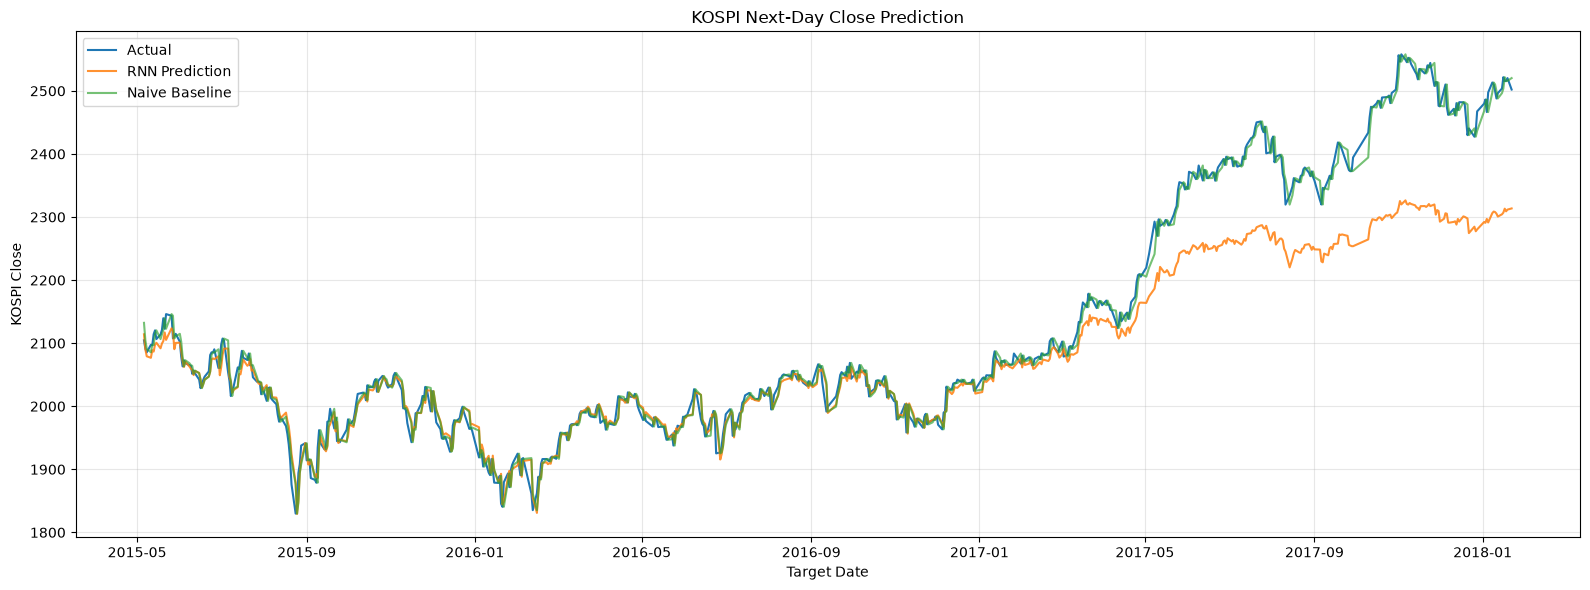

In [27]:
test_dates = pd.to_datetime(
    data.loc[idx_test, "Target_Date"].to_numpy()
)

plt.figure(figsize=(16, 6))
plt.plot(test_dates, true_close, label="Actual")
plt.plot(test_dates, pred_close, label="RNN Prediction", alpha=0.85)
plt.plot(test_dates, naive_pred, label="Naive Baseline", alpha=0.65)

plt.title("KOSPI Next-Day Close Prediction")
plt.xlabel("Target Date")
plt.ylabel("KOSPI Close")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

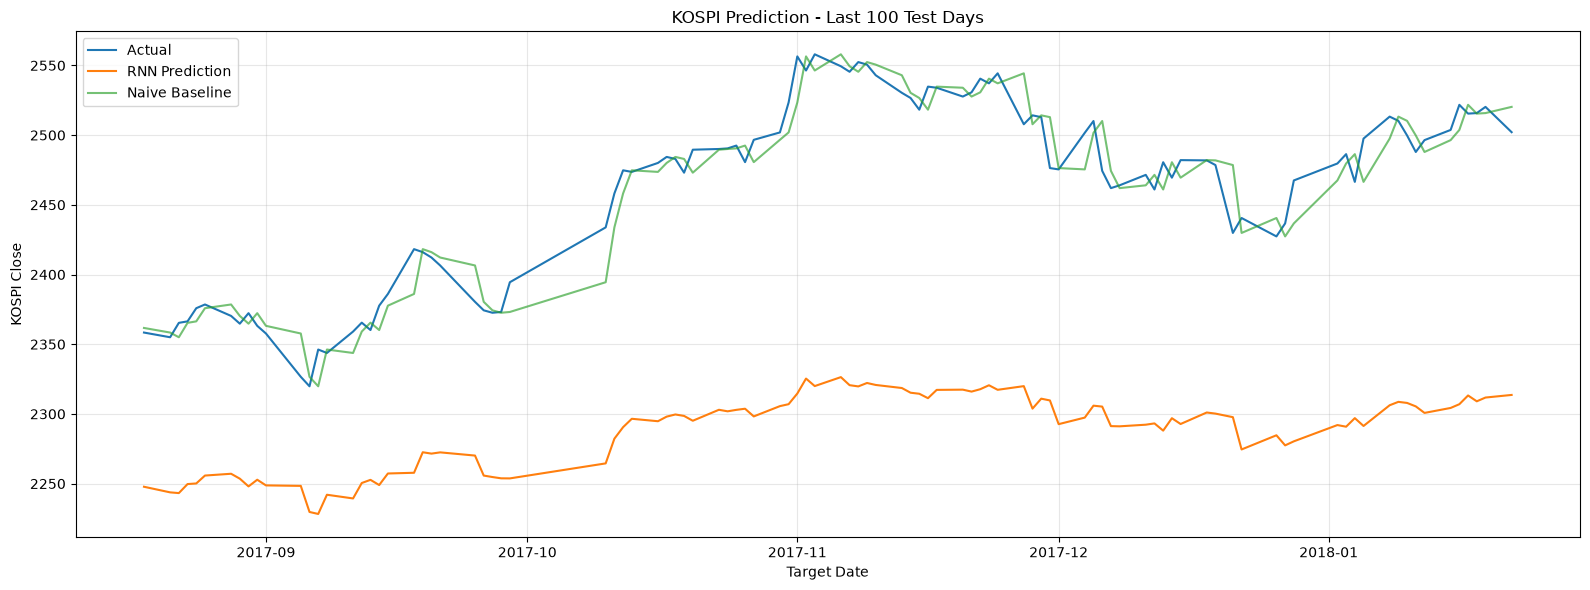

In [28]:
N_VIEW = min(100, len(test_dates))

plt.figure(figsize=(16, 6))

plt.plot(
    test_dates[-N_VIEW:],
    true_close[-N_VIEW:],
    label="Actual"
)

plt.plot(
    test_dates[-N_VIEW:],
    pred_close[-N_VIEW:],
    label="RNN Prediction"
)

plt.plot(
    test_dates[-N_VIEW:],
    naive_pred[-N_VIEW:],
    label="Naive Baseline",
    alpha=0.65
)

plt.title(f"KOSPI Prediction - Last {N_VIEW} Test Days")
plt.xlabel("Target Date")
plt.ylabel("KOSPI Close")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
result_df = pd.DataFrame({
    "Target_Date": test_dates,
    "Current_Close": current_close,
    "Actual_Next_Close": true_close,
    "RNN_Prediction": pred_close,
    "Naive_Prediction": naive_pred,
})

result_df["RNN_Error"] = (
    result_df["Actual_Next_Close"]
    - result_df["RNN_Prediction"]
)

result_df.tail(20)

,Target_Date,Current_Close,Actual_Next_Close,RNN_Prediction,Naive_Prediction,RNN_Error
645,2017-12-21,2478.530029,2429.830078,2297.676270,2478.530029,132.153809
646,2017-12-22,2429.830078,2440.540039,2274.505859,2429.830078,166.034180
647,2017-12-26,2440.540039,2427.340088,2284.678223,2440.540039,142.661865
648,2017-12-27,2427.340088,2436.669922,2277.437988,2427.340088,159.231934
649,2017-12-28,2436.669922,2467.489990,2280.341309,2436.669922,187.148682
650,2018-01-02,2467.489990,2479.649902,2292.009766,2467.489990,187.640137
651,2018-01-03,2479.649902,2486.350098,2290.832031,2479.649902,195.518066
652,2018-01-04,2486.350098,2466.459961,2296.974854,2486.350098,169.485107
653,2018-01-05,2466.459961,2497.520020,2291.356445,2466.459961,206.163574
654,2018-01-08,2497.520020,2513.280273,2306.225830,2497.520020,207.054443
